# Neutrino Mass Workspace


# Instructions per setup:
# On computer
Set the path of OriginalMeasurements to where you donwloaded this folder from the repo.
# On google colab
Keep the path as it is if you are running from google colab, just place the files under /content/


In [42]:
# Define new local paths

# Where the OriginalMeasurements are. Will be used only once here.
base_dir = "/content/"

# Where the csv version of all the measurements will be saved.
# PAY ATTENTION out_dir is used implicitly over the entire notebook.
out_dir = "/content/neutrino-mass-data/CleanedData"

##Imports


In [43]:
import glob
import os

from scipy.odr import ODR, Model, RealData
from scipy.special import gamma, digamma
import matplotlib.pyplot as plt
from scipy.stats import chi2
import scipy.constants
import pandas as pd
import numpy as np

# Run after paths are defined
Plese run the cells one after the other since some cells rely on prevous cell's results. If the entire notebook is collapsed, you can press the play button and it will run the cells by order on it's own :)

### File Conversion Code


In [44]:
# Create output directory if it does not exist
os.makedirs(out_dir, exist_ok=True)

# Find all .txt files in the specified folder
files_to_process = glob.glob(os.path.join(base_dir, "*.txt"))

if not files_to_process:
    print(f"No .txt files found in {base_dir}")
else:
    print(f"Found {len(files_to_process)} file(s) to process.\n")

for txt_path in sorted(files_to_process):
    file_name = os.path.basename(txt_path)
    print(f"Processing: {file_name}...")

    # Read the file lines, ignoring the header
    with open(txt_path, 'r', encoding='utf-8') as f:
        lines = f.readlines()

    # Skip the header (8 lines)
    filtered_lines = lines[8:]

    # Construct the output CSV file name
    csv_name = os.path.splitext(file_name)[0] + ".csv"
    csv_path = os.path.join(out_dir, csv_name)

    with open(csv_path, 'w', encoding='utf-8') as f_out:
        f_out.writelines(filtered_lines)

    print(f"Successfully saved: {csv_path}")

Found 7 file(s) to process.

Processing: 100 mV Pulser FINAL.txt...
Successfully saved: /content/neutrino-mass-data/CleanedData/100 mV Pulser FINAL.csv
Processing: 200 Times Amp 10-20-40-60-80-100 mV FINAL.txt...
Successfully saved: /content/neutrino-mass-data/CleanedData/200 Times Amp 10-20-40-60-80-100 mV FINAL.csv
Processing: Amc 241 Amp 250.txt...
Successfully saved: /content/neutrino-mass-data/CleanedData/Amc 241 Amp 250.csv
Processing: Amp 6-40-Mn54.txt...
Successfully saved: /content/neutrino-mass-data/CleanedData/Amp 6-40-Mn54.csv
Processing: Amp 6-40-Tl204.txt...
Successfully saved: /content/neutrino-mass-data/CleanedData/Amp 6-40-Tl204.csv
Processing: Amp6-40-Ba133.txt...
Successfully saved: /content/neutrino-mass-data/CleanedData/Amp6-40-Ba133.csv
Processing: Amp6-40-Cs137.txt...
Successfully saved: /content/neutrino-mass-data/CleanedData/Amp6-40-Cs137.csv


### Display all clean data

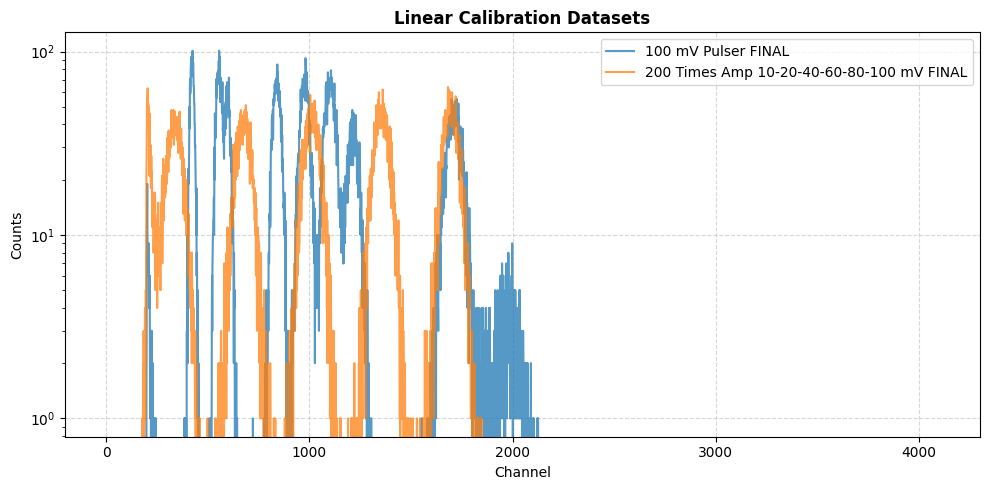

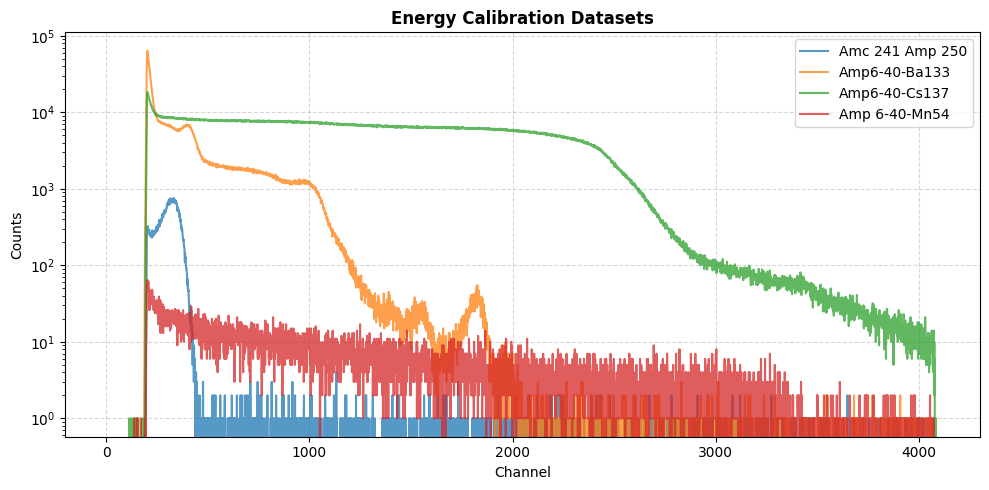

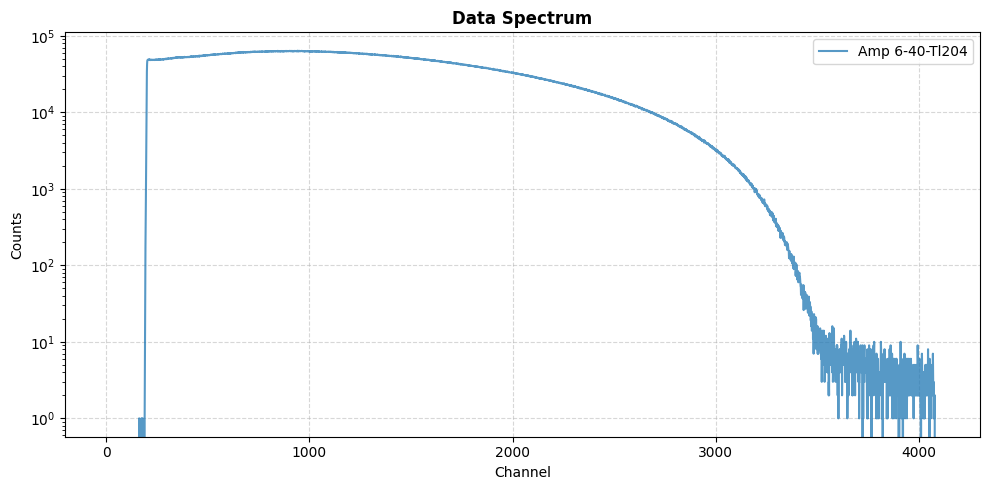

In [45]:
linear_calibration = [
    "100 mV Pulser FINAL.csv",
    "200 Times Amp 10-20-40-60-80-100 mV FINAL.csv",
]
energy_claibration = [
    "Amc 241 Amp 250.csv",
    "Amp6-40-Ba133.csv",
    "Amp6-40-Cs137.csv",
    "Amp 6-40-Mn54.csv",
]
data = ["Amp 6-40-Tl204.csv"]

# Helper function to plot a list of files
def plot_group(file_list, title):
    plt.figure(figsize=(10, 5))
    plotted = False
    for file_name in file_list:
        path = os.path.join(out_dir, file_name)
        if os.path.exists(path):
            df = pd.read_csv(path, header=None, names=["Counts"])
            plt.plot(df.index, df["Counts"], label=file_name.replace(".csv", ""), alpha=0.75)
            plotted = True
        else:
            print(f"File not found: {path}")

    if plotted:
        plt.title(title, fontsize=12, fontweight='bold')
        plt.xlabel("Channel")
        plt.ylabel("Counts")
        plt.yscale("log")
        plt.legend()
        plt.grid(True, linestyle="--", alpha=0.5)
        plt.tight_layout()
        plt.show()
    else:
        plt.close()

# Plot each list separately
plot_group(linear_calibration, "Linear Calibration Datasets")
plot_group(energy_claibration, "Energy Calibration Datasets")
plot_group(data, "Data Spectrum")

### Calibration Fits

####Setup Code

In [46]:
def gaussian_odr(p, x):
    """Standard Gaussian model for ODR: p = [amp, mean, sigma]."""
    amp, mean, sigma = p
    return amp * np.exp(-((x - mean) ** 2) / (2.0 * sigma ** 2))


def perform_gaussian_fit(file_name, label, ranges):
    path = os.path.join(out_dir, file_name)
    if not os.path.exists(path):
        print(f"File not found: {path}")
        empty = np.array([], dtype=float)
        return empty, empty, empty, empty, empty, empty

    df = pd.read_csv(path, header=None, names=["Counts"])
    y_data = df["Counts"].to_numpy(dtype=float)
    x_data = df.index.to_numpy(dtype=float)

    print(f"\nFitting results for {label} (Gaussian ODR Fit with Chi-Square & p-values):")

    fit_means, fit_amps, fit_sigmas = [], [], []
    err_means, err_amps, err_sigmas = [], [], []

    odr_model = Model(gaussian_odr)
    channel_err = 1.0 / np.sqrt(12.0)

    for i, (start, end) in enumerate(ranges):
        mask = (x_data >= start) & (x_data <= end)
        x_sub = x_data[mask]
        y_sub = y_data[mask]

        if len(x_sub) < 4:
            print(f"  Peak {i+1}: Insufficient data points in range ({start}, {end})")
            continue

        init_amp = np.max(y_sub)
        init_mean = x_sub[np.argmax(y_sub)]
        init_sigma = (end - start) / 4.0

        x_err = np.full_like(x_sub, channel_err)
        y_err = np.sqrt(np.where(y_sub > 0, y_sub, 1.0))

        try:
            data = RealData(x_sub, y_sub, sx=x_err, sy=y_err)
            odr_job = ODR(data, odr_model, beta0=[init_amp, init_mean, init_sigma])
            output = odr_job.run()

            fit_amp, fit_mean, fit_sigma = output.beta
            sd_amp, sd_mean, sd_sigma = output.sd_beta

            # Residuals and Chi-Square calculation
            y_fit_vals = gaussian_odr(output.beta, x_sub)
            residuals = y_sub - y_fit_vals
            chi_square = np.sum((residuals / y_err) ** 2)
            dof = len(x_sub) - len(output.beta)
            reduced_chi_square = chi_square / dof if dof > 0 else np.nan
            p_value = chi2.sf(chi_square, dof) if dof > 0 else np.nan

            fit_means.append(fit_mean)
            fit_amps.append(fit_amp)
            fit_sigmas.append(abs(fit_sigma))
            err_means.append(sd_mean)
            err_amps.append(sd_amp)
            err_sigmas.append(sd_sigma)

            print(
                f"  Peak {i+1}: Mean = {fit_mean:.2f} ± {sd_mean:.2f}, "
                f"Amplitude = {fit_amp:.2f} ± {sd_amp:.2f}, "
                f"Sigma = {abs(fit_sigma):.2f} ± {sd_sigma:.2f}"
            )
            print(
                f"          Chi-Sq = {chi_square:.2f}, DoF = {dof}, "
                f"Reduced Chi-Sq = {reduced_chi_square:.2f}, p-value = {p_value:.4e}"
            )

        except Exception as e:
            print(f"  Peak {i+1}: Fit failed for range ({start}, {end}) - {e}")

    return (
        np.asarray(fit_means, dtype=float),
        np.asarray(fit_amps, dtype=float),
        np.asarray(fit_sigmas, dtype=float),
        np.asarray(err_means, dtype=float),
        np.asarray(err_amps, dtype=float),
        np.asarray(err_sigmas, dtype=float),
    )


def display_gaussian_fits(file_name, label, color, ranges, peaks_x, peaks_y, peaks_sigma):
    path = os.path.join(out_dir, file_name)
    if not os.path.exists(path):
        return

    df = pd.read_csv(path, header=None, names=["Counts"])
    y_data = df["Counts"].to_numpy(dtype=float)
    x_data = df.index.to_numpy(dtype=float)

    # Compact size for single-column width in 2-column paper
    plt.figure(figsize=(3.5, 2.8))
    plt.plot(x_data, y_data, label=f"{label}", color=color, alpha=0.4, linewidth=0.8)

    # Plot pre-computed Gaussian curves directly
    y_offset = np.max(y_data) * 0.05
    for idx, (px, py, psigma) in enumerate(zip(peaks_x, peaks_y, peaks_sigma)):
        if len(peaks_x) == len(ranges):
            start, end = ranges[idx]
        else:
            start, end = px - 4.0 * psigma, px + 4.0 * psigma

        x_fit = np.linspace(start, end, 200)
        y_fit = gaussian_odr([py, px, psigma], x_fit)
        plt.plot(x_fit, y_fit, color="red", linestyle="-", linewidth=1.0)

        plt.scatter(px, py, color="red", edgecolor="black", s=15, zorder=5, linewidths=0.5)
        # Quick Patch to add height difference for the text boxes :)
        extra_y = 0
        # if idx == 2:
        #     extra_y += 5
        # if idx == 4:
        #     extra_y += 10

        plt.text(
            px,
            py + y_offset + extra_y,
            f"{px:.1f}",
            fontsize=6,
            fontweight="bold",
            ha="center",
            color="black",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="red", alpha=0.8, linewidth=0.5),
        )

    plt.title(f"{label} ODR Fit", fontsize=9, fontweight="bold")
    plt.xlabel("Channel", fontsize=8)
    plt.ylabel("Counts", fontsize=8)
    plt.xlim(0, 2000)
    plt.grid(True, linestyle="--", alpha=0.5, linewidth=0.5)
    plt.legend(fontsize=7, loc='upper right')
    plt.tick_params(axis='both', which='major', labelsize=7)
    plt.tight_layout()
    plt.show()


#### 200 Amp


Fitting results for 200 Times Amp (Gaussian ODR Fit with Chi-Square & p-values):
  Peak 1: Mean = 206.40 ± 0.53, Amplitude = 56.15 ± 5.54, Sigma = 5.18 ± 0.44
          Chi-Sq = 80.77, DoF = 18, Reduced Chi-Sq = 4.49, p-value = 6.2764e-10
  Peak 2: Mean = 336.76 ± 0.77, Amplitude = 39.49 ± 0.82, Sigma = 40.30 ± 0.79
          Chi-Sq = 131.80, DoF = 148, Reduced Chi-Sq = 0.89, p-value = 8.2615e-01
  Peak 3: Mean = 676.16 ± 0.49, Amplitude = 41.53 ± 0.67, Sigma = 37.22 ± 0.37
          Chi-Sq = 256.87, DoF = 398, Reduced Chi-Sq = 0.65, p-value = 1.0000e+00
  Peak 4: Mean = 1011.69 ± 0.55, Amplitude = 43.81 ± 0.76, Sigma = 38.02 ± 0.41
          Chi-Sq = 245.11, DoF = 298, Reduced Chi-Sq = 0.82, p-value = 9.8876e-01
  Peak 5: Mean = 1356.13 ± 0.50, Amplitude = 46.63 ± 0.75, Sigma = 37.86 ± 0.38
          Chi-Sq = 220.40, DoF = 298, Reduced Chi-Sq = 0.74, p-value = 9.9975e-01
  Peak 6: Mean = 1696.17 ± 0.49, Amplitude = 48.48 ± 0.77, Sigma = 37.99 ± 0.39
          Chi-Sq = 215.81, DoF = 2

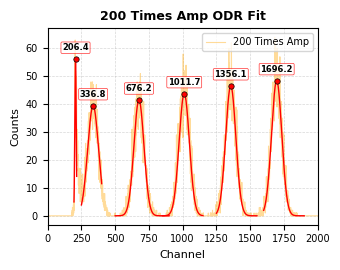

In [47]:
amp_200_ranges = [
    (195, 215),
    (250, 400),
    (500, 900),
    (850, 1150),
    (1250, 1550),
    (1600, 1900)
]

# Perform fit and retrieve centroids plus uncertainties

fit_means, fit_amps, fit_sigmas, err_means, err_amps, err_sigmas = perform_gaussian_fit(
    file_name="200 Times Amp 10-20-40-60-80-100 mV FINAL.csv",
    label="200 Times Amp",
    ranges=amp_200_ranges
)

# Save to a unique variable for dynamic access
amp_200_results = (fit_means, fit_amps, fit_sigmas, err_means, err_amps, err_sigmas)

# Display the plot using the returned peaks
display_gaussian_fits(
    file_name="200 Times Amp 10-20-40-60-80-100 mV FINAL.csv",
    label="200 Times Amp",
    color="orange",
    ranges=amp_200_ranges,
    peaks_x=fit_means,
    peaks_y=fit_amps,
    peaks_sigma=fit_sigmas,
)

#### 100mV Pulse


Fitting results for 100 mV Pulser (Gaussian ODR Fit with Chi-Square & p-values):
  Peak 1: Mean = 423.03 ± 0.23, Amplitude = 93.59 ± 2.60, Sigma = 9.69 ± 0.18
          Chi-Sq = 55.14, DoF = 48, Reduced Chi-Sq = 1.15, p-value = 2.2287e-01
  Peak 2: Mean = 573.44 ± 0.94, Amplitude = 62.57 ± 2.65, Sigma = 24.11 ± 0.58
          Chi-Sq = 983.68, DoF = 198, Reduced Chi-Sq = 4.97, p-value = 2.0729e-104
  Peak 3: Mean = 839.65 ± 0.29, Amplitude = 71.16 ± 1.33, Sigma = 18.64 ± 0.21
          Chi-Sq = 114.98, DoF = 148, Reduced Chi-Sq = 0.78, p-value = 9.7956e-01
  Peak 4: Mean = 977.36 ± 0.44, Amplitude = 68.09 ± 1.60, Sigma = 23.10 ± 0.34
          Chi-Sq = 203.67, DoF = 148, Reduced Chi-Sq = 1.38, p-value = 1.6497e-03
  Peak 5: Mean = 1101.09 ± 1.04, Amplitude = 65.58 ± 2.78, Sigma = 27.81 ± 0.91
          Chi-Sq = 697.38, DoF = 148, Reduced Chi-Sq = 4.71, p-value = 4.1255e-72
  Peak 6: Mean = 1211.11 ± 0.78, Amplitude = 33.67 ± 1.02, Sigma = 29.35 ± 0.64
          Chi-Sq = 201.51, DoF = 1

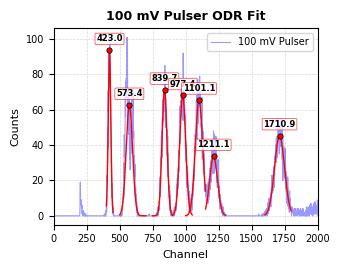

In [48]:
pulser_100_ranges = [
    (400, 450),
    (500, 700),
    (750, 900),
    (900, 1050),
    (1000, 1150),
    (1150, 1300),
    (1600, 1800)
]

# Perform fit and retrieve centroids plus uncertainties
fit_means, fit_amps, fit_sigmas, err_means, err_amps, err_sigmas = perform_gaussian_fit(
    file_name="100 mV Pulser FINAL.csv",
    label="100 mV Pulser",
    ranges=pulser_100_ranges
)

# Save to a unique variable for dynamic access
pulser_100_results = (fit_means, fit_amps, fit_sigmas, err_means, err_amps, err_sigmas)

# Display the plot using the returned peaks
display_gaussian_fits(
    file_name="100 mV Pulser FINAL.csv",
    label="100 mV Pulser",
    color="blue",
    ranges=pulser_100_ranges,
    peaks_x=fit_means,
    peaks_y=fit_amps,
    peaks_sigma=fit_sigmas,
)

### Linear Fit of system calibration

<>:64: SyntaxWarning: invalid escape sequence '\c'
<>:64: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_1023/1840770065.py:64: SyntaxWarning: invalid escape sequence '\c'
  f'$\chi^2_r$ = {chi_red:.2f}, p = {p_val:.2e}'


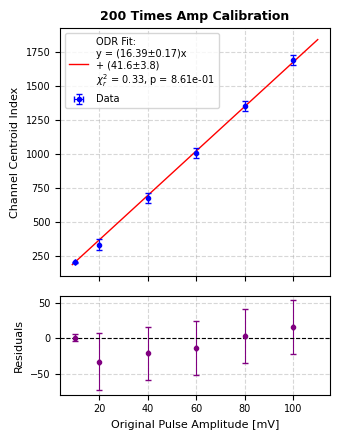

200 Times Amp Fit Equation: Channel = (16.3907 ± 0.1743) * X + (41.6434 ± 3.7666)
200 Times Amp Chi-Square = 1.3038, DoF = 4, Reduced Chi-Square = 0.3259, p-value = 8.6073e-01



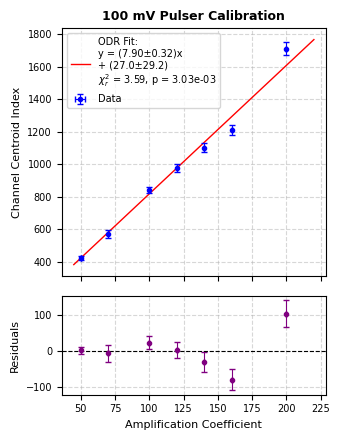

100 mV Pulser Fit Equation: Channel = (7.9048 ± 0.3154) * X + (27.0394 ± 29.2321)
100 mV Pulser Chi-Square = 17.9330, DoF = 5, Reduced Chi-Square = 3.5866, p-value = 3.0316e-03



In [49]:
# Map datasets to their dynamic variables from memory
calibration_data_source = {
    "200 Times Amp": {
        "peaks_x": amp_200_results[0],
        "sigmas": amp_200_results[2],
        "ref_x": [10, 20, 40, 60, 80, 100],
        "x_err_coef": 0.00751e-2,
        "x_unit": "Original Pulse Amplitude [mV]",
    },
    "100 mV Pulser": {
        "peaks_x": pulser_100_results[0],
        "sigmas": pulser_100_results[2],
        "ref_x": [50, 70, 100, 120, 140, 160, 200],
        "x_err_coef": 0.0031e-2,
        "x_unit": "Amplification Coefficient",
    }
}

# Linear function for ODR: y = m * x + c
def linear_func(p, x):
    m, c = p
    return m * x + c

for dataset_name, details in calibration_data_source.items():
    x_vals = np.array(details["ref_x"], dtype=float)
    x_err_coef = np.array(details["x_err_coef"], dtype=float)
    x_err = x_vals * x_err_coef
    y_vals = np.array(details["peaks_x"], dtype=float) # Fitted peak positions on channel index
    sigmas = np.array(details["sigmas"], dtype=float)

    # Y-error is the sqrt of the Gaussian fit's sigma
    y_err = sigmas

    # Perform Orthogonal Distance Regression (ODR)
    linear_model = Model(linear_func)
    data = RealData(x_vals, y_vals, sx=x_err, sy=y_err)
    init_m, init_c = np.polyfit(x_vals, y_vals, 1)
    odr_job = ODR(data, linear_model, beta0=[init_m, init_c])
    output = odr_job.run()

    m, c = output.beta
    m_err, c_err = output.sd_beta

    # Calculate Residuals
    y_pred = m * x_vals + c
    residuals = y_vals - y_pred

    # Calculate Chi-Square, Reduced Chi-Square, and p-value
    total_variance = y_err**2 + (m * x_err)**2
    chi_sq = np.sum((residuals**2) / total_variance)
    dof = len(x_vals) - len(output.beta)
    chi_red = chi_sq / dof if dof > 0 else np.nan
    p_val = chi2.sf(chi_sq, dof) if dof > 0 else np.nan

    # Plot Fit & Residuals - Optimized for a single-column width in a 2-column paper
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(3.5, 4.5), sharex=True, gridspec_kw={'height_ratios': [2.5, 1]})

    # Main plot
    ax1.errorbar(x_vals, y_vals, xerr=x_err, yerr=y_err, fmt='o', color='blue', label='Data', capsize=2, markersize=3, elinewidth=0.8, zorder=5)
    x_fit = np.linspace(min(x_vals)*0.9, max(x_vals)*1.1, 200)
    y_fit = m * x_fit + c

    legend_label = f'ODR Fit:\ny = ({m:.2f}±{m_err:.2f})x\n+ ({c:.1f}±{c_err:.1f})\n' \
                   f'$\chi^2_r$ = {chi_red:.2f}, p = {p_val:.2e}'
    ax1.plot(x_fit, y_fit, color='red', linewidth=1, label=legend_label)
    ax1.set_title(f"{dataset_name} Calibration", fontsize=9, fontweight='bold')
    ax1.set_ylabel("Channel Centroid Index", fontsize=8)
    ax1.legend(fontsize=7, loc='upper left')
    ax1.grid(True, linestyle="--", alpha=0.5)
    ax1.tick_params(axis='both', which='major', labelsize=7)

    # Residual plot
    ax2.errorbar(x_vals, residuals, xerr=x_err, yerr=y_err, fmt='o', color='purple', capsize=2, markersize=3, elinewidth=0.8)
    ax2.axhline(0, color='black', linestyle='--', linewidth=0.8)
    ax2.set_xlabel(f"{details['x_unit']}", fontsize=8)
    ax2.set_ylabel("Residuals", fontsize=8)
    ax2.grid(True, linestyle="--", alpha=0.5)
    ax2.tick_params(axis='both', which='major', labelsize=7)

    plt.tight_layout()
    plt.show()

    print(f"{dataset_name} Fit Equation: Channel = ({m:.4f} ± {m_err:.4f}) * X + ({c:.4f} ± {c_err:.4f})")
    print(f"{dataset_name} Chi-Square = {chi_sq:.4f}, DoF = {dof}, Reduced Chi-Square = {chi_red:.4f}, p-value = {p_val:.4e}\n")

### Expo-Gaussian Fitting for Energy Peak Centroids
Define the fitting ranges for each peak in the dictionary below, then run the cell to fit Gaussians to each specified interval.

####Setup

In [50]:
def gaussian_exp(p, x, x_start):
    """Gaussian + exponential background model: p = [amp, mean, sigma, decay, exp_amp]."""
    amp, mean, sigma, decay, exp_amp = p
    gauss = amp * np.exp(-((x - mean) ** 2) / (2.0 * sigma ** 2))
    exponent = exp_amp * np.exp(-decay * (x - x_start))
    return gauss + exponent


def fit_gaussian_exp_odr(file_name, label, color, ranges, plot=True):
    path = os.path.join(out_dir, file_name)
    if not os.path.exists(path):
        print(f"File not found: {path}")
        empty = np.array([], dtype=float)
        return empty, empty, empty, empty, empty, empty

    df = pd.read_csv(path, header=None, names=["Counts"])
    y_data = df["Counts"].to_numpy(dtype=float)
    x_data = df.index.to_numpy(dtype=float)

    if plot:
        # Formatted for a standard single-column width in a 2-column paper (3.5 in)
        plt.figure(figsize=(3.5, 2.8))
        plt.plot(x_data, y_data, label=f"{label}", color=color, alpha=0.4, linewidth=0.8)
        y_offset = np.max(y_data) * 0.05

    print(f"\nFitting results for {label} (Gaussian + Exp ODR):")

    peaks_x, peaks_y, sigmas = [], [], []
    errors_x, errors_y, errors_sigma = [], [], []
    channel_err = 1.0 / np.sqrt(12.0)

    for i, (start, end) in enumerate(ranges):
        mask = (x_data >= start) & (x_data <= end)
        x_sub = x_data[mask]
        y_sub = y_data[mask]

        if len(x_sub) < 6:
            print(f"  Peak {i+1}: Insufficient data points in range ({start}, {end})")
            continue

        init_amp = np.max(y_sub) - np.min(y_sub)
        init_mean = x_sub[np.argmax(y_sub)]
        init_sigma = (end - start) / 4.0
        init_decay = 0.01
        init_exp_amp = np.min(y_sub) if np.min(y_sub) > 0 else 1.0

        x_err = np.full_like(x_sub, channel_err)
        y_err = np.sqrt(np.where(y_sub > 0, y_sub, 1.0))

        try:
            odr_model = Model(lambda p, x, s=start: gaussian_exp(p, x, s))
            data = RealData(x_sub, y_sub, sx=x_err, sy=y_err)
            odr_job = ODR(
                data,
                odr_model,
                beta0=[init_amp, init_mean, init_sigma, init_decay, init_exp_amp],
            )
            output = odr_job.run()

            fit_amp, fit_mean, fit_sigma, fit_decay, fit_exp_amp = output.beta
            fit_sigma = abs(fit_sigma)
            sigma_err = output.sd_beta[2]

            peak_y = gaussian_exp(output.beta, fit_mean, start)
            err_x = channel_err
            err_y = 0.03 * peak_y

            peaks_x.append(fit_mean)
            peaks_y.append(peak_y)
            sigmas.append(fit_sigma)
            errors_x.append(err_x)
            errors_y.append(err_y)
            errors_sigma.append(sigma_err)

            print(
                f"  Peak {i+1}: Mean = {fit_mean:.2f} ± {err_x:.4f}, "
                f"Total Amplitude = {peak_y:.2f} ± {err_y:.2f}, "
                f"Sigma = {fit_sigma:.2f} ± {sigma_err:.2f}"
            )

            if plot:
                x_fit = np.linspace(start, end, 200)
                y_fit = gaussian_exp(output.beta, x_fit, start)
                plt.plot(x_fit, y_fit, color="red", linestyle="-", linewidth=1.0)
                plt.errorbar(
                    fit_mean,
                    peak_y,
                    xerr=err_x,
                    yerr=err_y,
                    fmt="o",
                    color="red",
                    ecolor="black",
                    elinewidth=0.8,
                    capsize=2,
                    markersize=3,
                    zorder=5,
                )
                extra_y = 0
                alt_ha = None
                if i == 1:
                  alt_ha = "right"
                if i == 2:
                  extra_y -= 2000
                if i == 4:
                  extra_y -= 2000
                  alt_ha = "left"
                plt.text(
                    # fit_mean+300, # More text patches :)
                    fit_mean,
                    peak_y + y_offset + extra_y,
                    f"{fit_mean:.1f}",
                    fontsize=6,
                    fontweight="bold",
                    ha=alt_ha if alt_ha else "center",
                    color="black",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="red", alpha=0.8, linewidth=0.5),
                )

        except Exception as e:
            print(f"  Peak {i+1}: Fit failed for range ({start}, {end}) - {e}")

    if plot:
        plt.title(f"{label} ODR Fit", fontsize=9, fontweight="bold")
        plt.xlabel("Channel", fontsize=8)
        plt.ylabel("Counts", fontsize=8)
        plt.grid(True, linestyle="--", alpha=0.5, linewidth=0.5)
        plt.legend(fontsize=7, loc='upper right')
        plt.yscale('log')
        plt.tick_params(axis='both', which='major', labelsize=7)
        plt.tight_layout(pad=1.2) # Extra vertical padding prevents overlap
        plt.show()

    return (
        np.asarray(peaks_x, dtype=float),
        np.asarray(peaks_y, dtype=float),
        np.asarray(sigmas, dtype=float),
        np.asarray(errors_x, dtype=float),
        np.asarray(errors_y, dtype=float),
        np.asarray(errors_sigma, dtype=float),
    )

####Execute


Fitting results for Amc 241 Amp 250 (Gaussian + Exp ODR):
  Peak 1: Mean = 321.73 ± 0.2887, Total Amplitude = 727.94 ± 21.84, Sigma = 35.99 ± 0.89


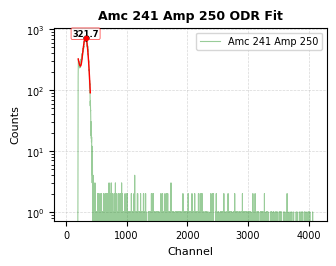


Fitting results for Amp6-40-Ba133 (Gaussian + Exp ODR):
  Peak 1: Mean = 390.67 ± 0.2887, Total Amplitude = 6904.35 ± 207.13, Sigma = 38.41 ± 0.64
  Peak 2: Mean = 1416.61 ± 0.2887, Total Amplitude = 23.97 ± 0.72, Sigma = 36.41 ± 12.82
  Peak 3: Mean = 1549.45 ± 0.2887, Total Amplitude = 25.36 ± 0.76, Sigma = 33.78 ± 10.29
  Peak 4: Mean = 1814.80 ± 0.2887, Total Amplitude = 37.06 ± 1.11, Sigma = 35.16 ± 0.93
  Peak 5: Mean = 1975.46 ± 0.2887, Total Amplitude = 3.11 ± 0.09, Sigma = 26.39 ± 5.47


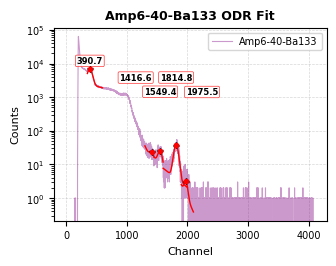


Fitting results for Amp6-40-Cs137 (Gaussian + Exp ODR):


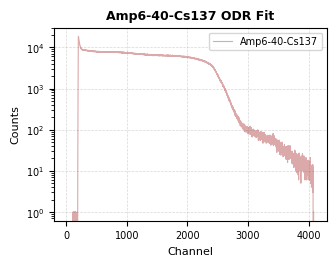


Fitting results for Amp 6-40-Mn54 (Gaussian + Exp ODR):


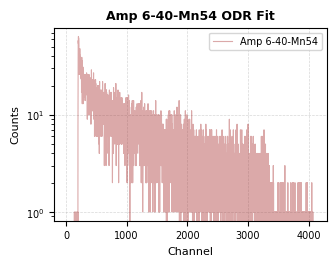

In [51]:
# Configure and run the fits
# The ranges of the visible peaks we found through trial and error.
source_configs = {
    "Amc 241 Amp 250.csv": {
        "label": "Amc 241 Amp 250",
        "color": "green",
        "ranges": [(200, 400)],
    },
    "Amp6-40-Ba133.csv": {
        "label": "Amp6-40-Ba133",
        "color": "purple",
        "ranges": [
            (350, 600),
            (1300, 1450),
            (1450, 1600),
            (1600, 2000),
            (1900,2100)
            ],
    },
    "Amp6-40-Cs137.csv": {
        "label": "Amp6-40-Cs137",
        "color": "brown",
        # "ranges": [(2000, 2500)],
        "ranges": [],
    },
    "Amp 6-40-Mn54.csv": {
        "label": "Amp 6-40-Mn54",
        "color": "brown",
        # "ranges": [(1000, 1200)],
        "ranges": [],
    },
}

fit_results = {}
for file_name, config in source_configs.items():
    px, py, sigmas, ex, ey, esigma = fit_gaussian_exp_odr(
        file_name=file_name,
        label=config["label"],
        color=config["color"],
        ranges=config["ranges"],
    )
    fit_results[file_name] = (px, py, sigmas, ex, ey, esigma)

In [52]:
# "Element": [(Ev,dEv,percnetage, dpercentage)]
# The energy levels we ended up using after tiral and error.
spectra = {
    "Am": [
        (59.5409,0.0001,35.9,0.4),
        ],
    "Ba": [
        (80.9979, 0.0011, 32.9, 0.3),
        (276.3989, 0.0012, 7.16, 0.05),
        (302.8508, 0.0005,18.34, 0.13),
        (356.0129, 0.0007,62.05, 0.19),
        (383.8491, 0.0008,8.94, 0.06),
        ],
    }

<>:71: SyntaxWarning: invalid escape sequence '\c'
<>:71: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_1023/902315280.py:71: SyntaxWarning: invalid escape sequence '\c'
  legend_label = f'ODR Linear Fit:\nE = ({m:.4f}±{m_err:.4f})*Ch\n+ ({c:.1f}±{c_err:.1f})\n$\chi^2_r$ = {reduced_chi_square:.2f}, p = {p_value:.2e}'


=== Energy Calibration ODR Fit Results ===
Slope (m)     = 0.195483 ± 0.002333 keV/channel
Intercept (c) = -0.6795 ± 3.4924 keV
Chi-Square    = 1.0507
DoF           = 4
Reduced Chi2  = 0.2627
p-value       = 9.0202e-01



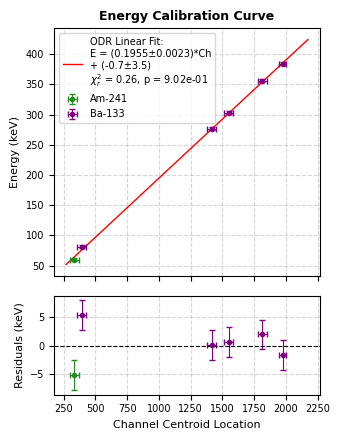

In [53]:
# 1. Gather the fitted centroids and errors, scaling the Amc-241 peak channel by 260/250
amc_raw_x = fit_results["Amc 241 Amp 250.csv"][0].item()
amc_raw_err_x = fit_results["Amc 241 Amp 250.csv"][2].item()  # Use the sigma as the error

scale_factor = 260.0 / 250.0
am_scaled_x = amc_raw_x * scale_factor
am_scaled_err_x = amc_raw_err_x * scale_factor

# Dynamically retrieve and include all Ba-133 fit results
ba_x = np.array(fit_results["Amp6-40-Ba133.csv"][0])
ba_err_x = np.array(fit_results["Amp6-40-Ba133.csv"][2])  # Use the sigma as the error

# Aligning centroids (X-axis in the calibration fit)
x_centroids = np.array([am_scaled_x] + list(ba_x))
x_errors = np.array([am_scaled_err_x] + list(ba_err_x))

# Dynamically retrieve reference energies from spectra (Y-axis in the calibration fit)
am_energies = np.array(spectra["Am"])
ba_energies = np.array(spectra["Ba"])

num_ba_peaks = len(ba_x)
y_energies = np.array([am_energies[0][0]] + list(ba_energies[:num_ba_peaks, 0]))
# y_errors = np.array([am_energies[0][1]] + list(ba_energies[:num_ba_peaks, 1]))

y_errors = np.array([9/np.sqrt(12)]*len([am_energies[0][1]] + list(ba_energies[:num_ba_peaks, 1])))

# 2. Define linear model: Energy = m * Channel + c
def linear_func(p, x):
    m, c = p
    return m * x + c

linear_model = Model(linear_func)
data = RealData(x_centroids, y_energies, sx=x_errors, sy=y_errors)

# Initial parameter guess
init_m, init_c = np.polyfit(x_centroids, y_energies, 1)
odr_job = ODR(data, linear_model, beta0=[init_m, init_c])
output = odr_job.run()

m, c = output.beta
m_err, c_err = output.sd_beta

# Calculate ODR Chi-Square and statistics
total_variance = y_errors**2 + (m * x_errors)**2
y_pred = m * x_centroids + c
residuals = y_energies - y_pred
chi_square = np.sum((residuals**2) / total_variance)
dof = len(x_centroids) - len(output.beta)
reduced_chi_square = chi_square / dof if dof > 0 else np.nan
p_value = 1.0 - chi2.cdf(chi_square, dof) if dof > 0 else np.nan

print("=== Energy Calibration ODR Fit Results ===")
print(f"Slope (m)     = {m:.6f} ± {m_err:.6f} keV/channel")
print(f"Intercept (c) = {c:.4f} ± {c_err:.4f} keV")
print(f"Chi-Square    = {chi_square:.4f}")
print(f"DoF           = {dof}")
print(f"Reduced Chi2  = {reduced_chi_square:.4f}")
print(f"p-value       = {p_value:.4e}\n")

# 3. Plotting the Fit and Residuals (Optimized for single column of a 2-column paper)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(3.5, 4.5), sharex=True, gridspec_kw={'height_ratios': [2.5, 1]})

# Plot Americium and Barium points with different colors
# Am-241: Green
ax1.errorbar(x_centroids[0], y_energies[0], xerr=x_errors[0], yerr=y_errors[0], fmt='o', color='forestgreen', label='Am-241', capsize=2, markersize=3, elinewidth=0.8, zorder=5)
# Ba-133: Purple
ax1.errorbar(x_centroids[1:], y_energies[1:], xerr=x_errors[1:], yerr=y_errors[1:], fmt='o', color='purple', label='Ba-133', capsize=2, markersize=3, elinewidth=0.8, zorder=5)

x_fit = np.linspace(min(x_centroids)*0.8, max(x_centroids)*1.1, 200)
y_fit = m * x_fit + c
legend_label = f'ODR Linear Fit:\nE = ({m:.4f}±{m_err:.4f})*Ch\n+ ({c:.1f}±{c_err:.1f})\n$\chi^2_r$ = {reduced_chi_square:.2f}, p = {p_value:.2e}'
ax1.plot(x_fit, y_fit, color='red', linewidth=1, label=legend_label)
ax1.set_title("Energy Calibration Curve", fontsize=9, fontweight='bold')
ax1.set_ylabel("Energy (keV)", fontsize=8)
ax1.legend(fontsize=7, loc='upper left')
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.tick_params(axis='both', which='major', labelsize=7)

# Residual Plot with different colors for each element
ax2.errorbar(x_centroids[0], residuals[0], xerr=x_errors[0], yerr=y_errors[0], fmt='o', color='forestgreen', capsize=2, markersize=3, elinewidth=0.8)
ax2.errorbar(x_centroids[1:], residuals[1:], xerr=x_errors[1:], yerr=y_errors[1:], fmt='o', color='purple', capsize=2, markersize=3, elinewidth=0.8)

ax2.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax2.set_xlabel("Channel Centroid Location", fontsize=8)
ax2.set_ylabel("Residuals (keV)", fontsize=8)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.tick_params(axis='both', which='major', labelsize=7)

plt.tight_layout()
plt.show()

#### Verify Values are usable for the rest of the notebook

In [54]:
m,m_err, c, c_err

(np.float64(0.19548331407401906),
 np.float64(0.002332733279942992),
 np.float64(-0.679514465031288),
 np.float64(3.4923788586854547))

####PileUpCleanup Setup Code

In [55]:
def remove_pileup_convolution(counts, ch_zero, endpoint_guess=3480, tail_range=(3500, 4050)):
    """
    Estimates and subtracts 2-fold random pileup via shifted self-convolution.

    Parameters
    ----------
    counts : 1D ndarray
        Raw (or background-subtracted) channel counts.
    ch_zero : float
        Channel corresponding to E = 0 keV from linear energy calibration (-intercept / slope).
    endpoint_guess : int
        Approximate channel where the true beta spectrum reaches zero.
    tail_range : tuple (start, end)
        Pure-pileup channel range above the endpoint used to fit the pileup scale factor.
    fit_flat_bg : bool
        If True, simultaneously fits a constant ambient background floor B in the tail.

    Returns
    -------
    cleaned_counts : 1D ndarray
        The pileup corrected counts.
    estimated_pileup : 1D ndarray
        The estimated pileup spectrum.
    bg_level : float
        The fitted background level.
    stats : dict
        Dictionary containing the fit statistics and parameters: alpha, bg_level, chi_sq, dof, chi_red, p_val.
    """
    counts = np.asarray(counts, dtype=float)
    n_ch = len(counts)
    shift = int(round(ch_zero))

    # Zero out channels above the endpoint so pileup isn't convolved with itself
    s_est = counts.copy()
    s_est[endpoint_guess:] = 0.0
    s_est = np.maximum(s_est, 0.0)

    # Compute discrete self-convolution and align with ADC zero-energy offset
    raw_conv = np.convolve(s_est, s_est)
    pileup_shape = np.zeros(n_ch, dtype=float)
    idx = np.arange(n_ch) + shift
    valid = (idx >= 0) & (idx < len(raw_conv))
    pileup_shape[valid] = raw_conv[idx[valid]]

    # Fit scale factor alpha (and optional constant background B) in the post-endpoint tail
    t_start, t_end = tail_range
    y_tail = counts[t_start:t_end]
    p_tail = pileup_shape[t_start:t_end]
    weights = 1.0 / np.maximum(y_tail, 1.0)  # Inverse-variance (Poisson) weights

    # Set the scaling factor according to the weights, the signal and the pileup in the tail.
    alpha = max(np.sum(weights * y_tail * p_tail) / np.sum(weights * p_tail ** 2), 0.0)

    estimated_pileup = alpha * pileup_shape
    cleaned_counts = np.maximum(counts - estimated_pileup, 0.0)

    # Calculate fit statistics
    y_pred = alpha * p_tail
    residuals = y_tail - y_pred
    chi_sq = np.sum(weights * (residuals ** 2))
    dof = len(y_tail) - 1
    chi_red = chi_sq / dof if dof > 0 else np.nan
    p_val = chi2.sf(chi_sq, dof) if dof > 0 else np.nan

    stats = {
        "alpha": alpha,
        "chi_sq": chi_sq,
        "dof": dof,
        "chi_red": chi_red,
        "p_val": p_val
    }

    return cleaned_counts, estimated_pileup, stats

####Pileup Cleanup Show

=== Pileup Tail Fit Parameters & Statistics ===
Scale Factor (alpha) = 2.647790e-12
Chi-Square           = 15514.2888
Degrees of Freedom   = 682
Reduced Chi-Square   = 22.7482
p-value              = 0.0000e+00



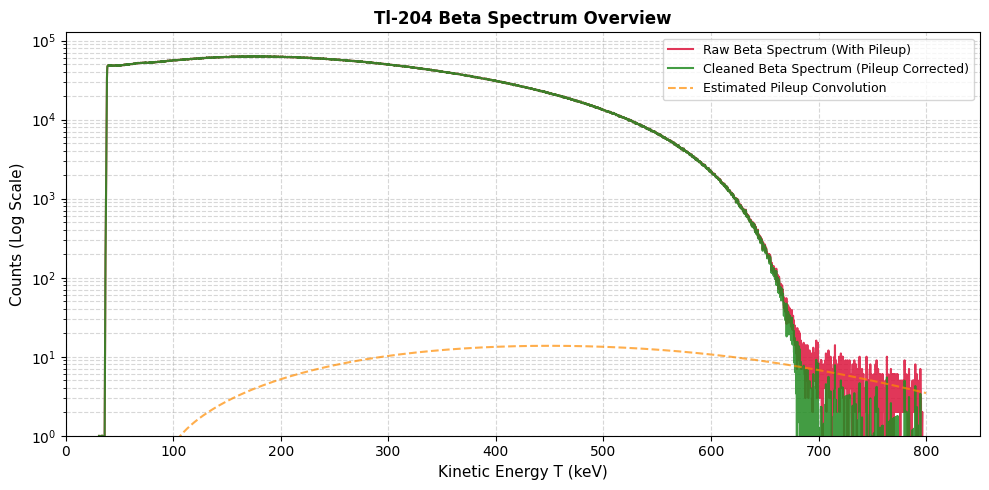

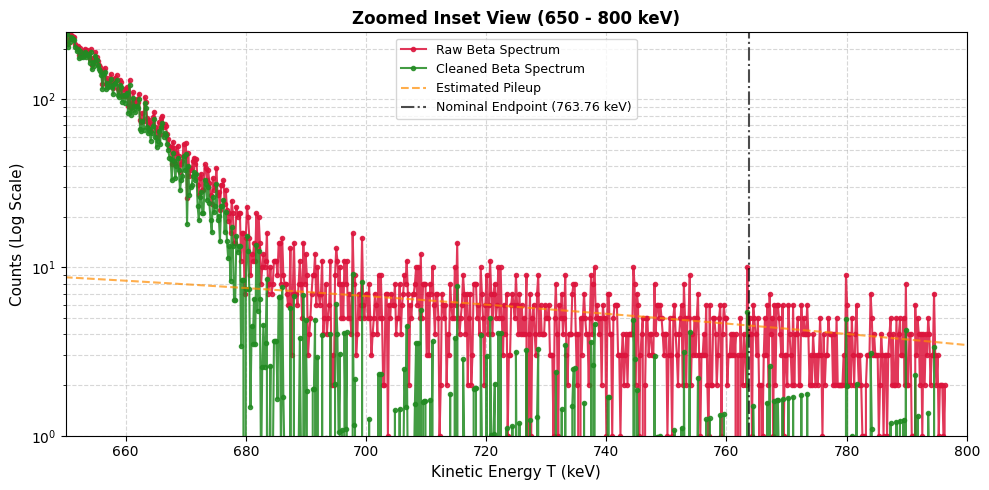

In [56]:
# Ensure calibration parameters and variables from global state are available
m_val = m
c_val = c
ch_zero = -c_val / m_val

file_name = "Amp 6-40-Tl204.csv"
path = os.path.join(out_dir, file_name)

# Zoom configuration parameters - adjust these to change focus
zoom_x_min = 650.0   # keV
zoom_x_max = 800.0   # keV
zoom_y_min = 1.0     # counts
zoom_y_max = 250.0  # counts

if os.path.exists(path):
    # Load the spectrum data
    df = pd.read_csv(path, header=None, names=["Counts"])
    raw_counts = df["Counts"].to_numpy(dtype=float)
    channels = df.index.to_numpy(dtype=float)

    # Convert channels to kinetic energy (keV)
    energy_kev = m_val * channels + c_val

    # Apply pileup cleanup and get fit statistics directly
    cleaned_counts, est_pileup, fit_stats = remove_pileup_convolution(
        raw_counts,
        ch_zero=ch_zero,
        endpoint_guess=3317,
        tail_range=(3317, 4000)
    )

    print("=== Pileup Tail Fit Parameters & Statistics ===")
    print(f"Scale Factor (alpha) = {fit_stats['alpha']:.6e}")
    print(f"Chi-Square           = {fit_stats['chi_sq']:.4f}")
    print(f"Degrees of Freedom   = {fit_stats['dof']}")
    print(f"Reduced Chi-Square   = {fit_stats['chi_red']:.4f}")
    print(f"p-value              = {fit_stats['p_val']:.4e}\n")

    # First Image: Full Beta Spectrum Overview
    plt.figure(figsize=(10, 5))
    plt.plot(energy_kev, raw_counts, color='crimson', alpha=0.85, label='Raw Beta Spectrum (With Pileup)')
    plt.plot(energy_kev, cleaned_counts, color='forestgreen', alpha=0.85, label='Cleaned Beta Spectrum (Pileup Corrected)')
    plt.plot(energy_kev, est_pileup, color='darkorange', linestyle='--', alpha=0.7, label='Estimated Pileup Convolution')

    plt.title("Tl-204 Beta Spectrum Overview", fontsize=12, fontweight='bold')
    plt.xlabel("Kinetic Energy T (keV)", fontsize=11)
    plt.ylabel("Counts (Log Scale)", fontsize=11)
    plt.xlim(0, 850)
    plt.ylim(1, max(raw_counts) * 2)
    plt.grid(True, which="both", linestyle="--", alpha=0.5)
    plt.legend(fontsize=9)
    plt.yscale('log')
    plt.tight_layout()
    plt.show()

    # Second Image: Zoomed-in Region (Log Scale)
    plt.figure(figsize=(10, 5))
    plt.plot(energy_kev, raw_counts, color='crimson', alpha=0.85, marker='o', markersize=3, label='Raw Beta Spectrum')
    plt.plot(energy_kev, cleaned_counts, color='forestgreen', alpha=0.85, marker='o', markersize=3, label='Cleaned Beta Spectrum')
    plt.plot(energy_kev, est_pileup, color='darkorange', linestyle='--', alpha=0.7, label='Estimated Pileup')

    # Mark the nominal physical endpoint of ~763.76 keV
    plt.axvline(763.76, color='black', linestyle='-.', alpha=0.7, label='Nominal Endpoint (763.76 keV)')

    plt.title(f"Zoomed Inset View ({zoom_x_min:.0f} - {zoom_x_max:.0f} keV)", fontsize=12, fontweight='bold')
    plt.xlabel("Kinetic Energy T (keV)", fontsize=11)
    plt.ylabel("Counts (Log Scale)", fontsize=11)
    plt.yscale('log')
    plt.xlim(zoom_x_min, zoom_x_max)
    plt.ylim(zoom_y_min, zoom_y_max)
    plt.grid(True, which="both", linestyle="--", alpha=0.5)
    plt.legend(fontsize=9)
    plt.tight_layout()
    plt.show()
else:
    print(f"File not found: {path}")

####KuriePlot Setup

In [57]:
# 1. Calibration and Experimental parameters
m_val = m
m_err = m_err
c_val = c
c_err = c_err

Z_daughter = 82.0
A = A_mass = 204.0
endpoint_kev = 763.76
rest_mass_kev = 510.99895069
alpha = fine_structure_constant = 1/137.036

ch_zero = -c_val / m_val

def fermi_function(z, energy_kev, mode):
  """Calculates the relativistic Fermi function using kinetic energy directly."""
  S = np.sqrt(1 - alpha**2 * z**2)
  R_fm = 1.2 * (A ** (1/3))
  rho = R_fm / 386.159
  E = 1.0 + energy_kev / rest_mass_kev
  p = np.sqrt(np.maximum(E**2 - 1.0, 1e-10))

  # Velocity calculation
  v = scipy.constants.c * np.sqrt(1.0 - (1.0 / E)**2)
  v = np.maximum(v, 1e-10)
  eta = z * scipy.constants.e**2 / (scipy.constants.hbar * v)

  gamma_mag_sq = np.abs(gamma(S + 1j * eta))**2
  gamma_den_sq = (gamma(2 * S + 1))**2
  match mode:
        case 'none':
            return 1
        case 'non-relativistic':
            return 2 * np.pi * eta / (1-np.exp(-2*np.pi * eta))
        case 'relativistic':
            return (2 * (1 + S) / gamma_den_sq) * ((2 * rho * p) ** (2 * S - 2)) * np.exp(np.pi * eta) * gamma_mag_sq

def calculate_fermi_function_error(
    z,
    energy_kev,
    d_energy_kev,
    d_z=0.0,
    radius_nat=None,
    d_radius_nat=0.0,
    mode='none',
):
  """
    Calculates the analytical propagated error of the relativistic Fermi function
    using the quadrature sum of partial derivatives multiplied by parameter errors:
        sigma_F = sqrt( sum_i ( (dF/dx_i) * sigma_x_i )^2 )
    """
  f_val = fermi_function(z, energy_kev, mode)

  w_kev = energy_kev + rest_mass_kev
  p_kev = np.sqrt(w_kev**2 - rest_mass_kev**2)
  s = np.sqrt(1.0 - (alpha * z) ** 2)
  eta = (alpha * z * w_kev) / p_kev

  # Shared derivative d(ln F)/d(eta)
  dlnf_deta = np.pi - 2.0 * np.imag(digamma(s + 1j * eta))

  # 1. Contribution from kinetic energy E
  dlnp_de = w_kev / (p_kev**2)
  deta_de = -(alpha * z * (rest_mass_kev**2)) / (p_kev**3)
  df_de = f_val * ((2.0 * s - 2.0) * dlnp_de + dlnf_deta * deta_de)
  error_terms = np.abs(df_de * d_energy_kev/rest_mass_kev)
  match mode:
        case 'none':
            return 0
        case 'non-relativistic':
            return deta_de*2*np.pi*((1-np.exp(-2 * np.pi * eta)) - eta*2*np.pi*(np.exp(-2 * np.pi * eta)))/((1-np.exp(-2*np.pi * eta))**2)* d_energy_kev/rest_mass_kev
        case 'relativistic':
            return error_terms

####KuriePlot


=== Linear Fit to Fermi-Kurie Plot (No Fermi Correction) ===
Fit Range      = 300.0 to 700.0 keV
Slope          = -0.279908 ± 0.001280
Intercept      = 182.5191 ± 0.7187
Extracted T_0  = 652.07 ± 3.87 keV
Chi-Square     = 60221.4117 (DoF = 2005)
Reduced Chi2   = 30.0356
p-value        = 0.0000e+00


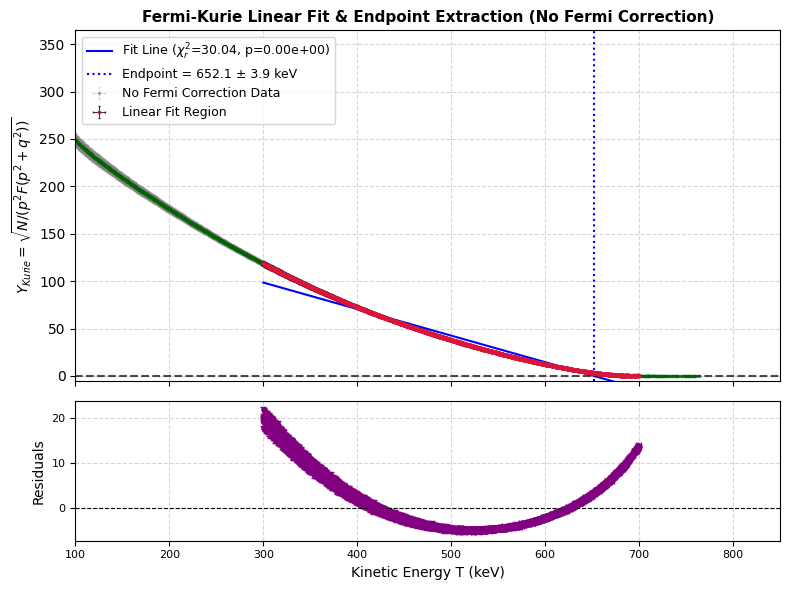


=== Linear Fit to Fermi-Kurie Plot (Non-Relativistic Fermi Correction) ===
Fit Range      = 300.0 to 700.0 keV
Slope          = -0.279908 ± 0.001280
Intercept      = 182.5191 ± 0.7187
Extracted T_0  = 652.07 ± 3.87 keV
Chi-Square     = 60221.4085 (DoF = 2005)
Reduced Chi2   = 30.0356
p-value        = 0.0000e+00


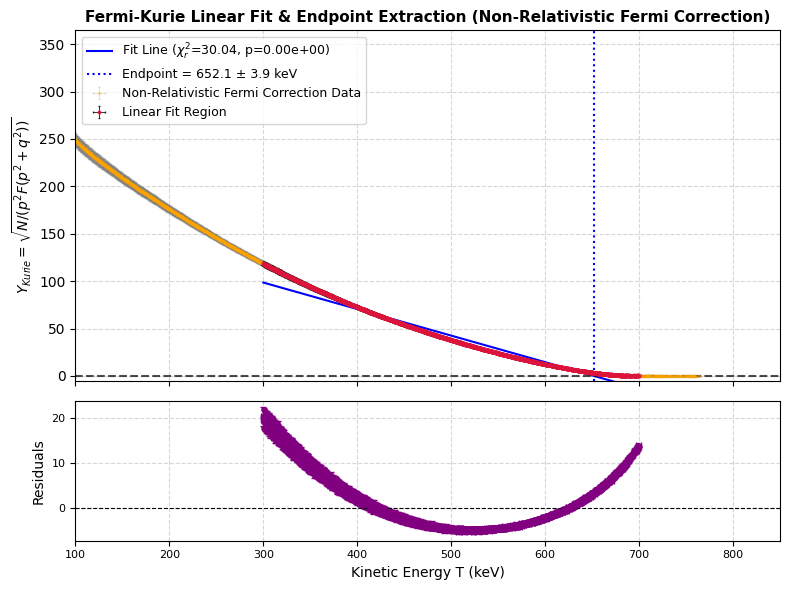


=== Linear Fit to Fermi-Kurie Plot (Relativistic Fermi Correction) ===
Fit Range      = 300.0 to 700.0 keV
Slope          = -0.100601 ± 0.000402
Intercept      = 65.8981 ± 0.2258
Extracted T_0  = 655.04 ± 3.37 keV
Chi-Square     = 46559.6965 (DoF = 2005)
Reduced Chi2   = 23.2218
p-value        = 0.0000e+00


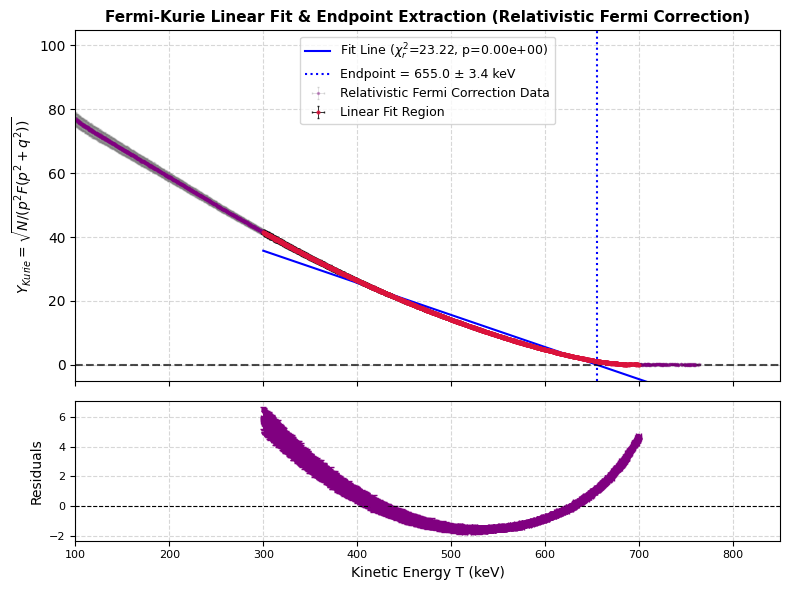

In [58]:
# --- 1. Globally Calculate Kinematics from Global Variables ---
valid_mask = (channels * m_val + c_val > 50.0) & (channels * m_val + c_val < endpoint_kev) & (cleaned_counts > 0)
fit_channels = channels[valid_mask]
fit_counts_clean = cleaned_counts[valid_mask]

T = m_val * fit_channels + c_val
T_err = np.full_like(T, 9 / np.sqrt(12))  # ORTEC resolution error

E = 1.0 + T / rest_mass_kev
p = np.sqrt(np.maximum(E**2 - 1.0, 1e-10))
E_0 = 1.0 + endpoint_kev / rest_mass_kev
true_q = np.maximum(E_0 - E, 0.0)
S1 = p**2 + true_q**2

# --- 2. ODR Fitting and Plotting Function with Residuals Subplot ---
def fit_and_plot_kurie(T_vals, T_errors, y_vals, y_errors, label, color_data):
    """
    Fits a linear model to the Kurie plot within the 300-700 keV range
    using ODR, calculates chi-square metrics, and plots both the main fit
    and its corresponding residuals.
    """
    start_E, end_E = 300.0, 700.0
    fit_range_mask = (T_vals >= start_E) & (T_vals <= end_E)
    T_fit = T_vals[fit_range_mask]
    T_fit_err = T_errors[fit_range_mask]
    y_fit = y_vals[fit_range_mask]
    y_fit_err = y_errors[fit_range_mask]

    # Linear model function: Y = slope * T + intercept
    def linear_model_func(p_params, x):
        slope, intercept = p_params
        return slope * x + intercept

    linear_model = Model(linear_model_func)
    data = RealData(T_fit, y_fit, sx=T_fit_err, sy=y_fit_err)

    # Initial parameter guess via standard linear regression
    init_slope, init_intercept = np.polyfit(T_fit, y_fit, 1)
    odr_job = ODR(data, linear_model, beta0=[init_slope, init_intercept])
    output = odr_job.run()

    slope, intercept = output.beta
    slope_err, intercept_err = output.sd_beta

    # Calculate experimental endpoint T_0 where Y = 0
    T_0 = -intercept / slope
    cov_matrix = output.cov_beta
    cov_slope_intercept = cov_matrix[0, 1] if cov_matrix is not None else 0.0
    T_0_err = abs(T_0) * np.sqrt((intercept_err / intercept)**2 + (slope_err / slope)**2 - 2 * cov_slope_intercept / (slope * intercept))

    # --- Chi-Square & p-value calculation (Orthogonal Distance formulation) ---
    y_pred = slope * T_fit + intercept
    residuals = y_fit - y_pred
    # Total variance incorporates both x-errors (scaled by slope) and y-errors
    total_variance = y_fit_err**2 + (slope * T_fit_err)**2
    chi_sq = np.sum((residuals**2) / total_variance)
    dof = len(T_fit) - len(output.beta)
    chi_red = chi_sq / dof if dof > 0 else np.nan
    p_val = chi2.sf(chi_sq, dof) if dof > 0 else np.nan

    print(f"\n=== Linear Fit to Fermi-Kurie Plot ({label}) ===")
    print(f"Fit Range      = {start_E} to {end_E} keV")
    print(f"Slope          = {slope:.6f} ± {slope_err:.6f}")
    print(f"Intercept      = {intercept:.4f} ± {intercept_err:.4f}")
    print(f"Extracted T_0  = {T_0:.2f} ± {T_0_err:.2f} keV")
    print(f"Chi-Square     = {chi_sq:.4f} (DoF = {dof})")
    print(f"Reduced Chi2   = {chi_red:.4f}")
    print(f"p-value        = {p_val:.4e}")

    # Create a publication-ready two-panel plot (Fit + Residuals)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw={'height_ratios': [2.5, 1]})

    # --- Main Plot (ax1) ---
    ax1.errorbar(T_vals, y_vals, xerr=T_errors, yerr=y_errors, fmt='o', color=color_data,
                 markersize=1.5, ecolor='gray', elinewidth=0.5, capsize=1, alpha=0.3, label=f'{label} Data')

    # Highlight the fit region
    ax1.errorbar(T_fit, y_fit, xerr=T_fit_err, yerr=y_fit_err, fmt='o', color='crimson',
                 markersize=2, ecolor='black', elinewidth=0.7, capsize=1, alpha=0.8, label='Linear Fit Region')

    # Plot fit line
    T_plot = np.linspace(300, 800, 200)
    y_plot = slope * T_plot + intercept
    ax1.plot(T_plot, y_plot, color='blue', linewidth=1.5,
             label=rf'Fit Line ($\chi^2_r$={chi_red:.2f}, p={p_val:.2e})')

    ax1.axhline(0, color='black', linestyle='--', alpha=0.7)
    ax1.axvline(T_0, color='blue', linestyle=':', label=f'Endpoint = {T_0:.1f} ± {T_0_err:.1f} keV')

    ax1.set_title(f"Fermi-Kurie Linear Fit & Endpoint Extraction ({label})", fontsize=11, fontweight='bold')
    ax1.set_ylabel(r"$Y_{Kurie} = \sqrt{N / (p^2 F (p^2+q^2))}$", fontsize=10)
    ax1.set_xlim(100, 850)
    ax1.set_ylim(-5, max(y_vals) * 1.1)
    ax1.grid(True, linestyle="--", alpha=0.5)
    ax1.legend(fontsize=9)

    # --- Residuals Plot (ax2) ---
    # Plots fit region residuals with custom styling
    ax2.errorbar(T_fit, residuals, xerr=T_fit_err, yerr=y_fit_err, fmt='o', color='purple',
                 capsize=2, markersize=3, elinewidth=0.8, label='Residuals')
    ax2.axhline(0, color='black', linestyle='--', linewidth=0.8)
    ax2.set_xlabel("Kinetic Energy T (keV)", fontsize=10)
    ax2.set_ylabel("Residuals", fontsize=10)
    ax2.grid(True, linestyle="--", alpha=0.5)
    ax2.tick_params(axis='both', which='major', labelsize=8)

    plt.tight_layout()
    plt.show()

    return T_0, T_0_err

# --- 3. Compute and Fit Each Fermi-Kurie Mode ---
modes = [
    ('none', 'darkgreen', 'No Fermi Correction'),
    ('non-relativistic', 'orange', 'Non-Relativistic Fermi Correction'),
    ('relativistic', 'purple', 'Relativistic Fermi Correction')
]

fit_endpoints = {}
for mode, color, label in modes:
    # Calculate Fermi function values and errors dynamically for each mode
    F_val = fermi_function(Z_daughter, T, mode)
    F_err = calculate_fermi_function_error(Z_daughter, T, T_err, mode=mode)

    # Calculate Kurie coordinates (incorporating unique first-forbidden shape factor S1 = p^2 + q^2)
    denom = p**2 * F_val * S1
    y_kurie = np.sqrt(fit_counts_clean / denom)

    counts_clean_err = np.sqrt(fit_counts_clean)

    # Analytical partial derivatives of Y with respect to p and q:
    # dY/dp = -Y * (1/p + p / (p^2 + q^2))
    # dY/dq = -Y * (q / (p^2 + q^2))
    dp_dq_err = 2.0 * 9.0 / np.sqrt(12.0)/rest_mass_kev

    dy_dp = (1.0 / np.maximum(p, 1e-10) + p / np.maximum(S1, 1e-10))
    dy_dq = (true_q / np.maximum(S1, 1e-10))

    # Combine standard error terms with added p and q error terms
    y_kurie_err = y_kurie * np.sqrt(
        ((counts_clean_err / np.maximum(2.0 * fit_counts_clean, 1e-10)))**2 +
        ((F_err / np.maximum(2.0 * F_val, 1e-10)))**2 +
        ((dy_dp + dy_dq)**2)*(dp_dq_err)**2
    )

    # Fit and plot
    T_0, T_0_err = fit_and_plot_kurie(T, T_err, y_kurie, y_kurie_err, label, color)
    fit_endpoints[mode] = (T_0, T_0_err)

##Create Fit Example for Report


Fitting results for Amp6-40-Ba133 (Gaussian + Exp ODR):
  Peak 1: Mean = 1814.80 ± 0.2887, Total Amplitude = 37.06 ± 1.11, Sigma = 35.16 ± 0.93


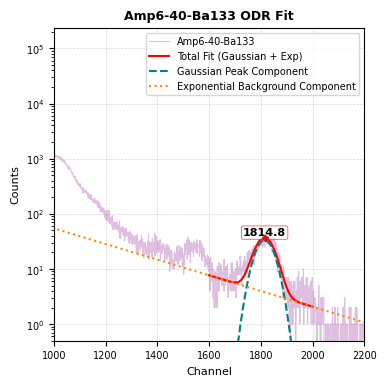

In [59]:
def gaussian_exp(p, x, x_start):
    """Gaussian + exponential background model: p = [amp, mean, sigma, decay, exp_amp]."""
    amp, mean, sigma, decay, exp_amp = p
    gauss = amp * np.exp(-((x - mean) ** 2) / (2.0 * sigma ** 2))
    exponent = exp_amp * np.exp(-decay * (x - x_start))
    return gauss + exponent


def fit_gaussian_exp_odr(file_name, label, color, ranges, plot=True):
    path = os.path.join(out_dir, file_name)
    if not os.path.exists(path):
        print(f"File not found: {path}")
        empty = np.array([], dtype=float)
        return empty, empty, empty, empty, empty, empty

    df = pd.read_csv(path, header=None, names=["Counts"])
    y_data = df["Counts"].to_numpy(dtype=float)
    x_data = df.index.to_numpy(dtype=float)

    if plot:
        # Formatted for a standard single-column width in a 2-column paper (3.5 in)
        plt.figure(figsize=(4, 4))
        # Lower the alpha of the raw data to make the fits significantly more visible
        plt.plot(x_data, y_data, label=f"{label}", color=color, alpha=0.25, linewidth=0.8)

    print(f"\nFitting results for {label} (Gaussian + Exp ODR):")

    peaks_x, peaks_y, sigmas = [], [], []
    errors_x, errors_y, errors_sigma = [], [], []
    channel_err = 1.0 / np.sqrt(12.0)

    for i, (start, end) in enumerate(ranges):
        mask = (x_data >= start) & (x_data <= end)
        x_sub = x_data[mask]
        y_sub = y_data[mask]

        if len(x_sub) < 6:
            print(f"  Peak {i+1}: Insufficient data points in range ({start}, {end})")
            continue

        init_amp = np.max(y_sub) - np.min(y_sub)
        init_mean = x_sub[np.argmax(y_sub)]
        init_sigma = (end - start) / 4.0
        init_decay = 0.01
        init_exp_amp = np.min(y_sub) if np.min(y_sub) > 0 else 1.0

        x_err = np.full_like(x_sub, channel_err)
        y_err = np.sqrt(np.where(y_sub > 0, y_sub, 1.0))

        try:
            odr_model = Model(lambda p, x, s=start: gaussian_exp(p, x, s))
            data = RealData(x_sub, y_sub, sx=x_err, sy=y_err)
            odr_job = ODR(
                data,
                odr_model,
                beta0=[init_amp, init_mean, init_sigma, init_decay, init_exp_amp],
            )
            output = odr_job.run()

            fit_amp, fit_mean, fit_sigma, fit_decay, fit_exp_amp = output.beta
            fit_sigma = abs(fit_sigma)
            sigma_err = output.sd_beta[2]

            peak_y = gaussian_exp(output.beta, fit_mean, start)
            err_x = channel_err
            err_y = 0.03 * peak_y

            peaks_x.append(fit_mean)
            peaks_y.append(peak_y)
            sigmas.append(fit_sigma)
            errors_x.append(err_x)
            errors_y.append(err_y)
            errors_sigma.append(sigma_err)

            print(
                f"  Peak {i+1}: Mean = {fit_mean:.2f} ± {err_x:.4f}, "
                f"Total Amplitude = {peak_y:.2f} ± {err_y:.2f}, "
                f"Sigma = {fit_sigma:.2f} ± {sigma_err:.2f}"
            )

            if plot:
                x_fit = np.linspace(start, end, 200)
                y_fit = gaussian_exp(output.beta, x_fit, start)

                # Plot individual components across the full fit range
                exp_x = np.linspace(0, 4096, 200)
                y_gauss_only = fit_amp * np.exp(-((x_fit - fit_mean) ** 2) / (2.0 * fit_sigma ** 2))
                y_exp_only = fit_exp_amp * np.exp(-fit_decay * (exp_x - start))

                plt.plot(x_fit, y_fit, color="red", linestyle="-", linewidth=1.5, label="Total Fit (Gaussian + Exp)")
                plt.plot(x_fit, y_gauss_only, color="teal", linestyle="--", linewidth=1.5, label="Gaussian Peak Component")
                plt.plot(exp_x, y_exp_only, color="darkorange", linestyle=":", linewidth=1.5, label="Exponential Background Component")

                plt.errorbar(
                    fit_mean,
                    peak_y,
                    xerr=err_x,
                    yerr=err_y,
                    fmt="o",
                    color="red",
                    ecolor="black",
                    elinewidth=0.8,
                    capsize=2,
                    markersize=3,
                    zorder=5,
                )
                plt.text(
                    fit_mean,
                    peak_y,
                    f"{fit_mean:.1f}",
                    fontsize=8,
                    fontweight="bold",
                    ha="center",
                    va="bottom",
                    color="black",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="red", alpha=0.8, linewidth=0.5),
                )

        except Exception as e:
            print(f"  Peak {i+1}: Fit failed for range ({start}, {end}) - {e}")

    if plot:
        plt.title(f"{label} ODR Fit", fontsize=9, fontweight="bold")
        plt.xlabel("Channel", fontsize=8)
        plt.ylabel("Counts", fontsize=8)
        plt.grid(True, linestyle="--", alpha=0.5, linewidth=0.5)
        plt.legend(fontsize=7, loc='upper right')
        plt.yscale('log')
        plt.xlim(1000, 2200)
        plt.ylim(bottom=0.5)
        plt.tick_params(axis='both', which='major', labelsize=7)
        plt.tight_layout(pad=1.2)
        plt.show()

    return (
        np.asarray(peaks_x, dtype=float),
        np.asarray(peaks_y, dtype=float),
        np.asarray(sigmas, dtype=float),
        np.asarray(errors_x, dtype=float),
        np.asarray(errors_y, dtype=float),
        np.asarray(errors_sigma, dtype=float),
    )


# Configure and run the fits
source_configs = {
    "Amp6-40-Ba133.csv": {
        "label": "Amp6-40-Ba133",
        "color": "purple",
        "ranges": [
            (1600, 2000),
            ],
    },
}

fit_results = {}
for file_name, config in source_configs.items():
    px, py, sigmas, ex, ey, esigma = fit_gaussian_exp_odr(
        file_name=file_name,
        label=config["label"],
        color=config["color"],
        ranges=config["ranges"],
    )
    fit_results[file_name] = (px, py, sigmas, ex, ey, esigma)